# HAI Feature Engineering Experiment

This notebook investigates the Week 1-4 HAI preprocessing pipeline without changing production scripts. It audits the prepared partitions, checks the scaling contract, measures missingness and feature quality, and constructs candidate temporal and process features for offline comparison.

Rules for this experiment:
- Fit preprocessing statistics on normal training rows only.
- Keep the attack-containing test partition out of feature selection.
- Use a bounded contiguous sample by default for an 8 GB development machine.
- Treat any feature as a candidate until its value is supported by diagnostics.
- Do not copy notebook changes into production code until the experiment results are reviewed.

In [1]:
from __future__ import annotations

import json
import platform
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
NODE_ID = "node_01"
PARTITION_ROOT = ROOT / "data" / "partitions" / NODE_ID
RESULT_ROOT = ROOT / "results" / "feature_engineering" / NODE_ID
RESULT_ROOT.mkdir(parents=True, exist_ok=True)
MAX_ROWS = 100_000
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
pd.set_option("display.max_columns", 80)
print({"root": str(ROOT), "node": NODE_ID, "max_rows": MAX_ROWS, "python": platform.python_version()})

{'root': 'c:\\Users\\LENOVO\\OneDrive\\Desktop\\Agentic_Mesh', 'node': 'node_01', 'max_rows': 100000, 'python': '3.12.4'}


## 1. Load a contiguous train/test sample

The rows remain in temporal order. A contiguous sample is important because rolling features and derivatives must not be calculated after shuffling. Set `MAX_ROWS = None` only when the machine has enough memory for the full experiment.

In [2]:
def load_partition(name: str, max_rows: int | None = MAX_ROWS) -> pd.DataFrame:
    frame = pd.read_parquet(PARTITION_ROOT / f"{name}.parquet")
    if max_rows is not None:
        frame = frame.iloc[:max_rows].copy()
    frame["time"] = pd.to_datetime(frame["time"], utc=True, errors="coerce")
    return frame.reset_index(drop=True)

train = load_partition("train")
test = load_partition("test")
feature_columns = [c for c in train.columns if c not in {"time", "label"}]
assert feature_columns == [c for c in test.columns if c not in {"time", "label"}]
print("train:", train.shape, "test:", test.shape, "features:", len(feature_columns))
display(pd.DataFrame({"train_labels": train["label"].value_counts(), "test_labels": test["label"].value_counts()}))

train: (100000, 40) test: (100000, 40) features: 38


,train_labels,test_labels
label,,
0,100000.0,97262
1,NaN,2738


## 2. Audit the current preprocessing contract

The production path currently scales HAI data in `scripts/prepare_data.py` and applies a scaler artifact again in `edge/data_loader.py`. This cell measures whether the stored partitions are already bounded and whether applying the artifact changes them materially. A large difference confirms a double-scaling risk; a small difference still indicates that the ownership of scaling is ambiguous and should be resolved before retraining.

In [3]:
scaler_path = ROOT / "results" / "scalers" / f"{NODE_ID}.json"
scaler_payload = json.loads(scaler_path.read_text(encoding="utf-8")) if scaler_path.exists() else None
values = train[feature_columns].apply(pd.to_numeric, errors="coerce")
normal_values = values.loc[train["label"] == 0]
audit = pd.DataFrame({
    "feature": feature_columns,
    "missing": values.isna().sum().to_numpy(),
    "finite": np.isfinite(values.to_numpy(dtype=float)).all(axis=0),
    "unique": values.nunique(dropna=True).to_numpy(),
    "minimum": values.min().to_numpy(),
    "maximum": values.max().to_numpy(),
    "normal_minimum": normal_values.min().to_numpy(),
    "normal_maximum": normal_values.max().to_numpy(),
    "normal_std": normal_values.std().to_numpy(),
})
audit["constant_or_near_constant"] = audit["unique"] <= 2
audit["outside_unit_interval"] = (audit["minimum"] < 0) | (audit["maximum"] > 1)
display(audit.sort_values(["missing", "normal_std"], ascending=[False, True]).head(50))
print("stored range:", float(values.min().min()), float(values.max().max()))
print("scaler artifact:", scaler_path if scaler_payload else "not found")
if scaler_payload:
    artifact_min = np.asarray(scaler_payload["minimum"], dtype=float)
    artifact_max = np.asarray(scaler_payload["maximum"], dtype=float)
    print("artifact range:", float(artifact_min.min()), float(artifact_max.max()))

,feature,missing,finite,unique,minimum,maximum,normal_minimum,normal_maximum,normal_std,constant_or_near_constant,outside_unit_interval
25,P1_PCV02D,0,True,1,0.000000,0.000000,0.000000,0.000000,0.000000,True,False
29,P1_PP01AD,0,True,1,0.000000,0.000000,0.000000,0.000000,0.000000,True,False
30,P1_PP01AR,0,True,1,0.000000,0.000000,0.000000,0.000000,0.000000,True,False
31,P1_PP01BD,0,True,1,0.000000,0.000000,0.000000,0.000000,0.000000,True,False
32,P1_PP01BR,0,True,1,0.000000,0.000000,0.000000,0.000000,0.000000,True,False
33,P1_PP02D,0,True,1,0.000000,0.000000,0.000000,0.000000,0.000000,True,False
34,P1_PP02R,0,True,1,0.000000,0.000000,0.000000,0.000000,0.000000,True,False
35,P1_STSP,0,True,1,0.000000,0.000000,0.000000,0.000000,0.000000,True,False
26,P1_PCV02Z,0,True,30,0.861101,1.000000,0.861101,1.000000,0.020785,False,False
27,P1_PIT01,0,True,1425,0.051473,0.988511,0.051473,0.988511,0.039777,False,False


stored range: 0.0 1.0
scaler artifact: c:\Users\LENOVO\OneDrive\Desktop\Agentic_Mesh\results\scalers\node_01.json
artifact range: 0.0 1.0


In [4]:
def apply_artifact_once(frame: pd.DataFrame, payload: dict) -> pd.DataFrame:
    minimum = np.asarray(payload["minimum"], dtype=float)
    maximum = np.asarray(payload["maximum"], dtype=float)
    scale = np.where(maximum > minimum, maximum - minimum, 1.0)
    matrix = frame[feature_columns].to_numpy(dtype=float)
    transformed = np.clip((matrix - minimum) / scale, 0.0, 1.0)
    return pd.DataFrame(transformed, columns=feature_columns, index=frame.index)

if scaler_payload:
    transformed_once = apply_artifact_once(train, scaler_payload)
    original = train[feature_columns].to_numpy(dtype=float)
    scale_delta = np.abs(original - transformed_once.to_numpy())
    print("mean absolute change after artifact:", float(scale_delta.mean()))
    print("fraction changed beyond 1e-6:", float((scale_delta > 1e-6).mean()))
    print("fraction clipped at boundaries:", float(((transformed_once.to_numpy() <= 0) | (transformed_once.to_numpy() >= 1)).mean()))
else:
    print("No scaler artifact found; create it before running the scaling comparison.")

mean absolute change after artifact: 0.0
fraction changed beyond 1e-6: 0.0
fraction clipped at boundaries: 0.2756952631578947


## 3. Missing values and imputation audit

The current loader uses forward fill followed by backward fill. The experiment below measures missingness before imputation and records whether a feature has long missing runs. Long runs should not be silently filled without a quality flag.

In [5]:
def missing_run_lengths(series: pd.Series) -> list[int]:
    missing = series.isna().to_numpy()
    runs = []
    current = 0
    for value in missing:
        if value:
            current += 1
        elif current:
            runs.append(current)
            current = 0
    if current:
        runs.append(current)
    return runs

missing_audit = []
for column in feature_columns:
    runs = missing_run_lengths(train[column])
    missing_audit.append({
        "feature": column,
        "missing_count": int(train[column].isna().sum()),
        "missing_fraction": float(train[column].isna().mean()),
        "longest_missing_run": max(runs, default=0),
    })
missing_audit = pd.DataFrame(missing_audit).sort_values("missing_fraction", ascending=False)
display(missing_audit.head(20))
print("rows with at least one missing feature:", int(train[feature_columns].isna().any(axis=1).sum()))

,feature,missing_count,missing_fraction,longest_missing_run
0,P1_B2004,0,0.0,0
28,P1_PIT02,0,0.0,0
21,P1_LCV01Z,0,0.0,0
22,P1_LIT01,0,0.0,0
23,P1_PCV01D,0,0.0,0
24,P1_PCV01Z,0,0.0,0
25,P1_PCV02D,0,0.0,0
26,P1_PCV02Z,0,0.0,0
27,P1_PIT01,0,0.0,0
29,P1_PP01AD,0,0.0,0


rows with at least one missing feature: 0


## 4. Candidate feature engineering

The candidate set is deliberately generic so it can be tested without hard-coding unverified process equations:
- first difference and absolute first difference for abrupt changes,
- rolling mean and standard deviation for local operating regime,
- rolling deviation from the local mean,
- binary transition indicators for status-like features.

The first `ROLLING_WINDOW` rows are dropped because their rolling context is incomplete.

In [8]:
ROLLING_WINDOW = 15
binary_feature_columns = [
    column for column in feature_columns
    if train[column].dropna().nunique() <= 2
]

def engineer_features(
    frame: pd.DataFrame,
    columns: list[str],
    rolling_window: int = ROLLING_WINDOW,
    binary_columns: list[str] = binary_feature_columns,
) -> pd.DataFrame:
    output = frame[["time", "label"]].copy()
    numeric = frame[columns].apply(pd.to_numeric, errors="coerce").ffill().bfill()
    feature_blocks = {}
    for column in columns:
        series = numeric[column]
        delta = series.diff()
        rolling = series.rolling(rolling_window, min_periods=rolling_window)
        mean = rolling.mean()
        std = rolling.std().fillna(0.0)
        feature_blocks[column] = series
        feature_blocks[f"{column}__delta"] = delta
        feature_blocks[f"{column}__abs_delta"] = delta.abs()
        feature_blocks[f"{column}__rolling_mean"] = mean
        feature_blocks[f"{column}__rolling_std"] = std
        feature_blocks[f"{column}__local_deviation"] = series - mean
        if column in binary_columns:
            feature_blocks[f"{column}__transition"] = series.ne(series.shift()).astype(float)
    output = pd.concat([output, pd.DataFrame(feature_blocks, index=frame.index)], axis=1)
    return output.dropna().reset_index(drop=True)

train_engineered = engineer_features(train, feature_columns)
test_engineered = engineer_features(test, feature_columns)
engineered_columns = [c for c in train_engineered.columns if c not in {"time", "label"}]
assert engineered_columns == [c for c in test_engineered.columns if c not in {"time", "label"}]
print("binary features:", len(binary_feature_columns))
print("baseline features:", len(feature_columns), "engineered features:", len(engineered_columns))
display(train_engineered.head())

binary features: 8
baseline features: 38 engineered features: 236


,time,label,P1_B2004,P1_B2004__delta,P1_B2004__abs_delta,P1_B2004__rolling_mean,P1_B2004__rolling_std,P1_B2004__local_deviation,P1_B2016,P1_B2016__delta,P1_B2016__abs_delta,P1_B2016__rolling_mean,P1_B2016__rolling_std,P1_B2016__local_deviation,P1_B3004,P1_B3004__delta,P1_B3004__abs_delta,P1_B3004__rolling_mean,P1_B3004__rolling_std,P1_B3004__local_deviation,P1_B3005,P1_B3005__delta,P1_B3005__abs_delta,P1_B3005__rolling_mean,P1_B3005__rolling_std,P1_B3005__local_deviation,P1_B4002,P1_B4002__delta,P1_B4002__abs_delta,P1_B4002__rolling_mean,P1_B4002__rolling_std,P1_B4002__local_deviation,P1_B4005,P1_B4005__delta,P1_B4005__abs_delta,P1_B4005__rolling_mean,P1_B4005__rolling_std,P1_B4005__local_deviation,P1_B400B,P1_B400B__delta,...,P1_PP01BR,P1_PP01BR__delta,P1_PP01BR__abs_delta,P1_PP01BR__rolling_mean,P1_PP01BR__rolling_std,P1_PP01BR__local_deviation,P1_PP01BR__transition,P1_PP02D,P1_PP02D__delta,P1_PP02D__abs_delta,P1_PP02D__rolling_mean,P1_PP02D__rolling_std,P1_PP02D__local_deviation,P1_PP02D__transition,P1_PP02R,P1_PP02R__delta,P1_PP02R__abs_delta,P1_PP02R__rolling_mean,P1_PP02R__rolling_std,P1_PP02R__local_deviation,P1_PP02R__transition,P1_STSP,P1_STSP__delta,P1_STSP__abs_delta,P1_STSP__rolling_mean,P1_STSP__rolling_std,P1_STSP__local_deviation,P1_STSP__transition,P1_TIT01,P1_TIT01__delta,P1_TIT01__abs_delta,P1_TIT01__rolling_mean,P1_TIT01__rolling_std,P1_TIT01__local_deviation,P1_TIT02,P1_TIT02__delta,P1_TIT02__abs_delta,P1_TIT02__rolling_mean,P1_TIT02__rolling_std,P1_TIT02__local_deviation
0,2020-07-11 00:00:14+00:00,0,0.989609,0.0,0.0,0.989609,0.0,0.0,0.290169,-0.002480,0.002480,0.302982,0.009235,-0.012813,0.357101,0.0,0.0,0.357101,0.0,0.0,0.482697,0.0,0.0,0.482697,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.990834,-0.000694,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.331076,0.006753,0.006753,0.331979,0.003490,-0.000902,0.139665,0.000000,0.000000,0.139851,0.001658,-0.000186
1,2020-07-11 00:00:15+00:00,0,0.989609,0.0,0.0,0.989609,0.0,0.0,0.287816,-0.002353,0.002353,0.301021,0.009114,-0.013204,0.357101,0.0,0.0,0.357101,0.0,0.0,0.482697,0.0,0.0,0.482697,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.991776,0.000942,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.324324,-0.006753,0.006753,0.331528,0.004012,-0.007205,0.139665,0.000000,0.000000,0.139851,0.001658,-0.000186
2,2020-07-11 00:00:16+00:00,0,0.989609,0.0,0.0,0.989609,0.0,0.0,0.288785,0.000968,0.000968,0.299179,0.008557,-0.010394,0.357101,0.0,0.0,0.357101,0.0,0.0,0.482697,0.0,0.0,0.482697,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.992718,0.000942,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.331076,0.006753,0.006753,0.331078,0.003612,-0.000001,0.139665,0.000000,0.000000,0.139851,0.001658,-0.000186
3,2020-07-11 00:00:17+00:00,0,0.989609,0.0,0.0,0.989609,0.0,0.0,0.280776,-0.008009,0.008009,0.296841,0.008468,-0.016065,0.357101,0.0,0.0,0.357101,0.0,0.0,0.482697,0.0,0.0,0.482697,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.993709,0.000991,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.324324,-0.006753,0.006753,0.330177,0.003489,-0.005853,0.142458,0.002794,0.002794,0.140037,0.001787,0.002421
4,2020-07-11 00:00:18+00:00,0,0.989609,0.0,0.0,0.989609,0.0,0.0,0.279536,-0.001240,0.001240,0.294990,0.009035,-0.015454,0.357101,0.0,0.0,0.357101,0.0,0.0,0.482697,0.0,0.0,0.482697,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.997128,0.003420,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.331076,0.006753,0.006753,0.330177,0.003489,0.000900,0.139665,-0.002794,0.002794,0.140037,0.001787,-0.000372


## 5. Compare scaler candidates on normal training data

This is a preprocessing comparison, not final model selection. The fit is restricted to normal training rows. The same transformation is then applied to the held-out test sample only for distribution inspection.

In [9]:
def scaler_summary(train_frame: pd.DataFrame, test_frame: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    normal = train_frame.loc[train_frame["label"] == 0, columns].to_numpy(dtype=float)
    test_values = test_frame[columns].to_numpy(dtype=float)
    candidates = {
        "minmax": MinMaxScaler(),
        "standard": StandardScaler(),
        "robust": RobustScaler(quantile_range=(5, 95)),
    }
    rows = []
    for name, scaler in candidates.items():
        scaler.fit(normal)
        transformed = scaler.transform(test_values)
        rows.append({
            "scaler": name,
            "normal_mean_abs": float(np.abs(scaler.transform(normal)).mean()),
            "test_outside_3sigma": float(np.mean(np.abs(transformed) > 3)),
            "test_min": float(np.min(transformed)),
            "test_max": float(np.max(transformed)),
        })
    return pd.DataFrame(rows)

baseline_scalers = scaler_summary(train, test, feature_columns)
engineered_scalers = scaler_summary(train_engineered, test_engineered, engineered_columns)
display(baseline_scalers)
display(engineered_scalers)

,scaler,normal_mean_abs,test_outside_3sigma,test_min,test_max
0,minmax,0.402268,0.000788,-2.024455,340.973001
1,standard,0.654160,0.004059,-21.011213,2275.439369
2,robust,0.204704,0.001289,-7.600274,567.621669


,scaler,normal_mean_abs,test_outside_3sigma,test_min,test_max
0,minmax,0.280640,0.000276,-87.009974,543.542009
1,standard,0.461115,0.008710,-1123.512368,2505.810149
2,robust,0.170850,0.002872,-322.724279,709.152068


## 6. Univariate separability screen

This screen ranks individual candidate features by ROC-AUC and PR-AUC on the bounded test sample. It is descriptive only: it must not be used to select features based on the final test set. A proper next experiment should repeat this ranking on a validation split and reserve the complete test partition for one final report.

In [10]:
def feature_separability(frame: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    labels = frame["label"].to_numpy(dtype=int)
    rows = []
    for column in columns:
        values = frame[column].to_numpy(dtype=float)
        finite = np.isfinite(values)
        if finite.sum() == 0 or np.unique(labels[finite]).size < 2:
            continue
        score = np.abs(values) if column.endswith(("__delta", "__local_deviation")) else values
        try:
            auc = roc_auc_score(labels[finite], score[finite])
            pr_auc = average_precision_score(labels[finite], score[finite])
        except ValueError:
            continue
        rows.append({
            "feature": column,
            "roc_auc": max(float(auc), 1.0 - float(auc)),
            "pr_auc": float(pr_auc),
            "missing_fraction": float((~finite).mean()),
        })
    return pd.DataFrame(rows).sort_values(["roc_auc", "pr_auc"], ascending=False)

baseline_screen = feature_separability(test, feature_columns)
engineered_screen = feature_separability(test_engineered, engineered_columns)
display(baseline_screen.head(20))
display(engineered_screen.head(30))

,feature,roc_auc,pr_auc,missing_fraction
4,P1_B4002,0.665843,0.041676,0.0
13,P1_FCV03Z,0.650135,0.069282,0.0
12,P1_FCV03D,0.637092,0.070268,0.0
11,P1_FCV02Z,0.636012,0.021219,0.0
7,P1_B4022,0.633333,0.038064,0.0
36,P1_TIT01,0.631179,0.061444,0.0
18,P1_FT03,0.616705,0.054426,0.0
19,P1_FT03Z,0.616434,0.054349,0.0
0,P1_B2004,0.610274,0.024912,0.0
9,P1_FCV01Z,0.605416,0.035091,0.0


,feature,roc_auc,pr_auc,missing_fraction
136,P1_LIT01__rolling_std,0.854772,0.490085,0.0
76,P1_FCV03D__rolling_std,0.844516,0.440532,0.0
137,P1_LIT01__local_deviation,0.835752,0.480450,0.0
112,P1_FT03__rolling_std,0.835309,0.308710,0.0
118,P1_FT03Z__rolling_std,0.835166,0.278871,0.0
77,P1_FCV03D__local_deviation,0.809197,0.427925,0.0
133,P1_LIT01__delta,0.782925,0.426425,0.0
134,P1_LIT01__abs_delta,0.782925,0.426425,0.0
167,P1_PIT01__rolling_std,0.777990,0.229301,0.0
124,P1_LCV01D__rolling_std,0.776173,0.442120,0.0


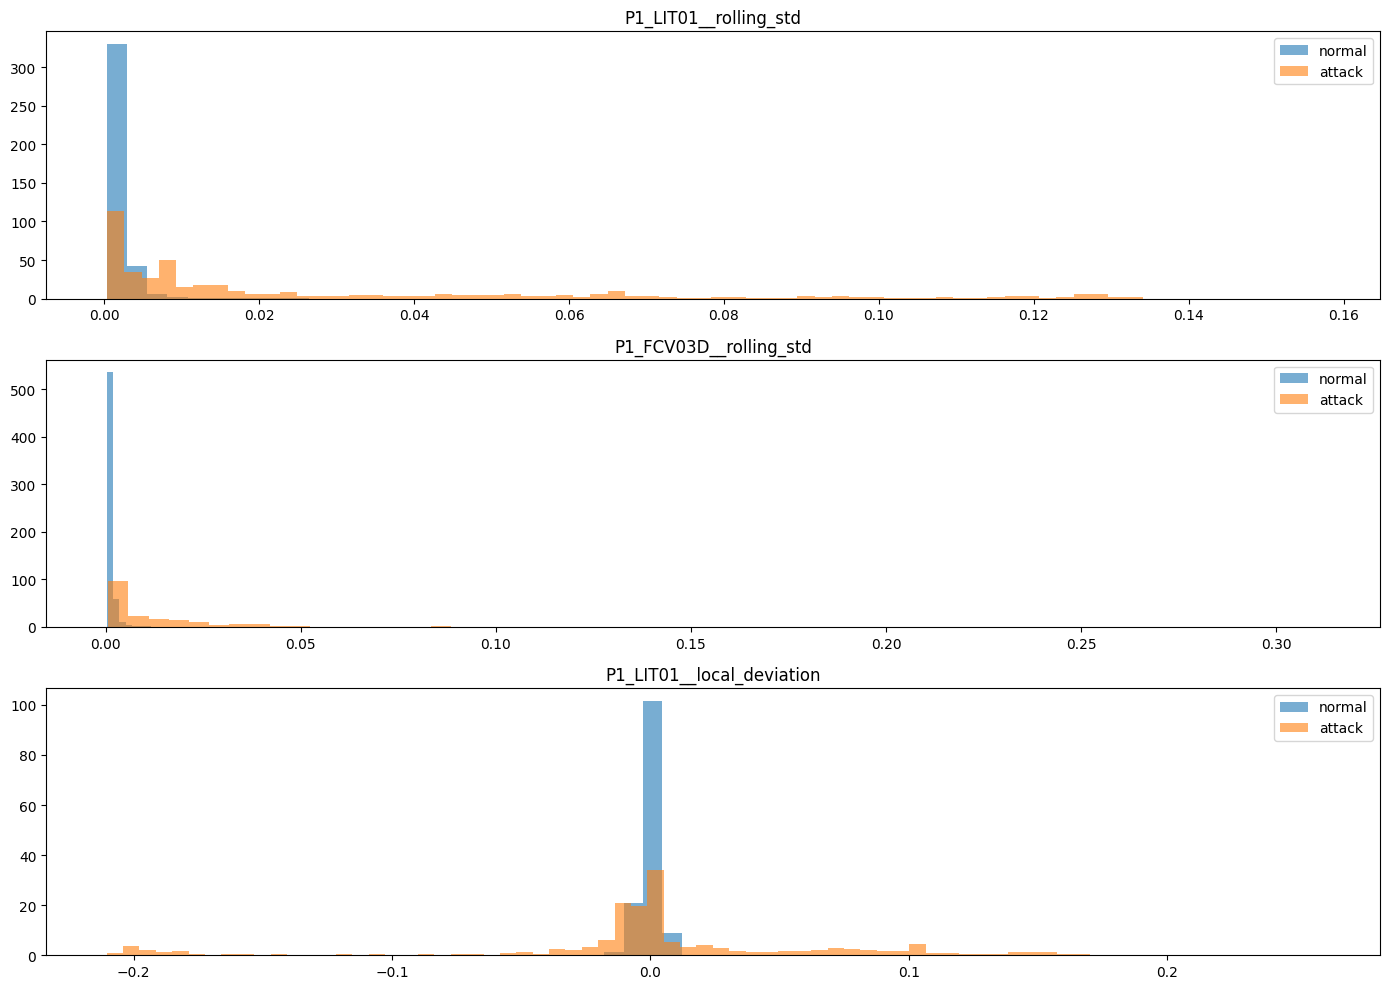

In [11]:
top_features = engineered_screen.head(12)["feature"].tolist()
if top_features:
    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=False)
    for axis, column in zip(axes, top_features[:3]):
        normal = test_engineered.loc[test_engineered["label"] == 0, column]
        attack = test_engineered.loc[test_engineered["label"] == 1, column]
        axis.hist(normal, bins=60, alpha=0.6, density=True, label="normal")
        axis.hist(attack, bins=60, alpha=0.6, density=True, label="attack")
        axis.set_title(column)
        axis.legend()
    fig.tight_layout()
    plt.show()

## 7. Export experiment artifacts

These are analysis artifacts only. They do not replace the prepared partitions or production scaler files. The output records the diagnostics needed to decide which changes are worth promoting.

In [12]:
audit.to_csv(RESULT_ROOT / "feature_audit.csv", index=False)
missing_audit.to_csv(RESULT_ROOT / "missingness_audit.csv", index=False)
baseline_screen.to_csv(RESULT_ROOT / "baseline_feature_separability.csv", index=False)
engineered_screen.to_csv(RESULT_ROOT / "engineered_feature_separability.csv", index=False)
summary = {
    "node_id": NODE_ID,
    "max_rows": MAX_ROWS,
    "baseline_feature_count": len(feature_columns),
    "engineered_feature_count": len(engineered_columns),
    "rolling_window": ROLLING_WINDOW,
    "train_shape": list(train.shape),
    "test_shape": list(test.shape),
    "scaler_artifact": str(scaler_path),
    "top_engineered_features": top_features,
}
(RESULT_ROOT / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps(summary, indent=2))

{
  "node_id": "node_01",
  "max_rows": 100000,
  "baseline_feature_count": 38,
  "engineered_feature_count": 236,
  "rolling_window": 15,
  "train_shape": [
    100000,
    40
  ],
  "test_shape": [
    100000,
    40
  ],
  "scaler_artifact": "c:\\Users\\LENOVO\\OneDrive\\Desktop\\Agentic_Mesh\\results\\scalers\\node_01.json",
  "top_engineered_features": [
    "P1_LIT01__rolling_std",
    "P1_FCV03D__rolling_std",
    "P1_LIT01__local_deviation",
    "P1_FT03__rolling_std",
    "P1_FT03Z__rolling_std",
    "P1_FCV03D__local_deviation",
    "P1_LIT01__delta",
    "P1_LIT01__abs_delta",
    "P1_PIT01__rolling_std",
    "P1_LCV01D__rolling_std",
    "P1_FT03__local_deviation",
    "P1_FT01__rolling_std"
  ]
}


## Decision checklist

Before changing production code, review:
1. Is scaling owned by exactly one stage?
2. Are missing values rare enough for imputation, or should missingness flags be added?
3. Do temporal features improve separability on a validation split, not only the test sample?
4. Do candidate features remain useful across nodes 01, 02, and 03?
5. Does the feature count remain practical for the VAE and DP-SGD memory budget?
6. Are process-specific residual features supported by engineering knowledge rather than correlation alone?

Only the approved decisions from this notebook should later be implemented in `scripts/prepare_data.py`, `edge/preprocessing.py`, or `edge/data_loader.py`.